# Модель платформи цифрового двійника НСПТ

**Мова моделі:** SysML v2 (SysML v2 Pilot Implementation, ядро Jupyter).

## Крок 9. Модель вимог

Усі функціональні (FR) і нефункціональні (NFR) вимоги з `docs/requirements.md` з тими самими ідентифікаторами, згруповані за доменами ISO 23247:

| Пакет | Домен ISO 23247 | Вимоги |
|---|---|---|
| `DCE_DeviceCommunication` | зв'язок із пристроями | FR-01, FR-08, NFR-04 |
| `DTE_DigitalTwin` | цифровий двійник | FR-03, FR-04, FR-06, FR-07, NFR-01, NFR-03 |
| `UE_User` | користувач | FR-05, NFR-02, NFR-06 |
| `CrossCutting` | наскрізна сутність | FR-02, NFR-05 |

Запуск: **Kernel → Restart Kernel and Run All Cells**.

In [1]:
package PumpStationTwin_Requirements {
    doc /* Вимоги до платформи цифрового двійника НСПТ, згруповані за доменами ISO 23247. */

    package DCE_DeviceCommunication {
        doc /* Домен зв'язку з пристроями: збирання даних і керування пристроями. */

        requirement <'FR-01'> telemetryCollection {
            doc /* Платформа приймає всі сигнали реєстру (S-01 – S-16) через MQTT із частотами з реєстру;
                 * кожне повідомлення містить ідентифікатор сигналу, мітку часу й значення;
                 * у разі втрати зв'язку шлюз буферизує телеметрію щонайменше 1 год. */
        }
        requirement <'FR-08'> remoteControl {
            doc /* Оператор змінює уставку тиску (4,0–6,0 бар), пускає й зупиняє Н1 і Н2, перемикає режим;
                 * команда виконана лише коли reported = desired, без підтвердження за 10 с — тривога;
                 * у сервісному режимі команди відхиляються. */
        }
        requirement <'NFR-04'> commandLatency {
            doc /* Від надсилання команди до підтвердження станцією ≤ 3 с для 95 % команд. */
        }
    }

    package DTE_DigitalTwin {
        doc /* Домен цифрового двійника: застосунки й служби, доступ до ресурсів, функціонування й керування. */

        requirement <'FR-03'> stateSync {
            doc /* Платформа зберігає reported і desired стан насосів і станції;
                 * понад 5 с без даних — стан позначається як застарілий. */
        }
        requirement <'FR-04'> historyStorage {
            doc /* Історія сигналів за рівнями гарячий / теплий / холодний; журнал подій, тривог і команд. */
        }
        requirement <'FR-06'> alarms {
            doc /* Тривоги за порогами (тиск на виході < 3 бар, вібрація > 4,5 мм/с) і за подіями
                 * (сухий хід, аварія насоса) з квитуванням оператором. */
        }
        requirement <'FR-07'> analytics {
            doc /* Енергоефективність кожного насоса (кВт·год на 1 м³) і виявлення аномалій вібрації
                 * та температури; результати — лише рекомендації. */
        }
        requirement <'NFR-01'> syncLatency {
            doc /* Від мітки часу на шлюзі до оновлення стану двійника в API ≤ 500 мс для 95 % оновлень. */
        }
        requirement <'NFR-03'> scalability {
            doc /* Перехід з 1 до 10 станцій збільшує 95-й перцентиль затримки синхронізації
                 * не більш ніж на 30 % і без втрати повідомлень. */
        }
    }

    package UE_User {
        doc /* Домен користувача: подання стану оператору та інженеру. */

        requirement <'FR-05'> visualization {
            doc /* Дашборд поточних значень, тренди будь-якого сигналу, 3D-сцена станції
                 * з кольором стану насоса. */
        }
        requirement <'NFR-02'> endToEndLatency {
            doc /* Значення на екрані ≤ 1 с після зчитування на шлюзі для 95 % оновлень;
                 * аварійна тривога на екрані ≤ 2 с після події — для кожної події. */
        }
        requirement <'NFR-06'> sceneSmoothness {
            doc /* ≥ 99 % кадрів 3D-сцени формуються за ≤ 33,3 мс; оновлення стану не блокують рендеринг. */
        }
    }

    package CrossCutting {
        doc /* Наскрізна сутність: захищеність, якість даних, взаємодійність. */

        requirement <'FR-02'> dataQuality {
            doc /* Платформа відкидає дублікати й значення поза діапазоном реєстру
                 * і фіксує їх у журналі якості даних. */
        }
        requirement <'NFR-05'> security {
            doc /* MQTT і API — лише через TLS з автентифікацією; команди — лише роль «оператор»;
                 * 100 % команд у журналі. */
        }
    }
}


Package PumpStationTwin_Requirements (32e17a84-7f58-44d7-9272-9a138d2ef9e7)


### Діаграми вимог за доменами ISO 23247

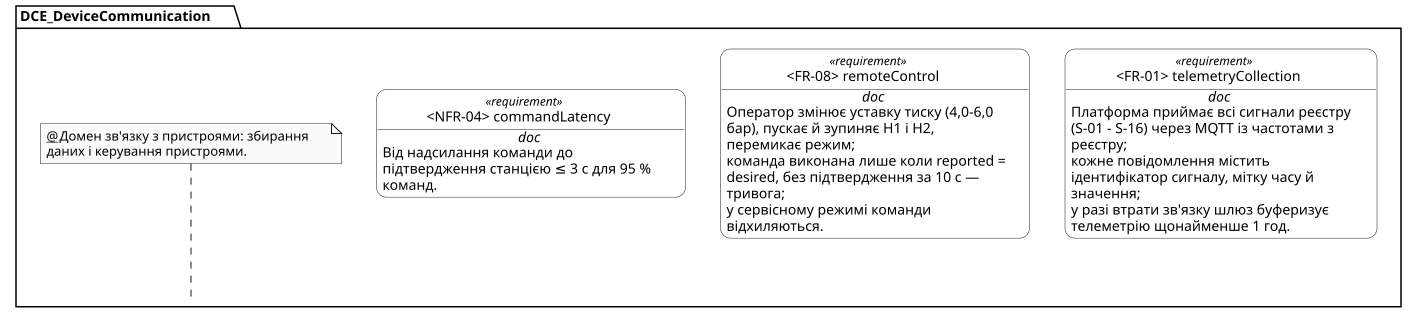

In [2]:
%viz --view=tree PumpStationTwin_Requirements::DCE_DeviceCommunication

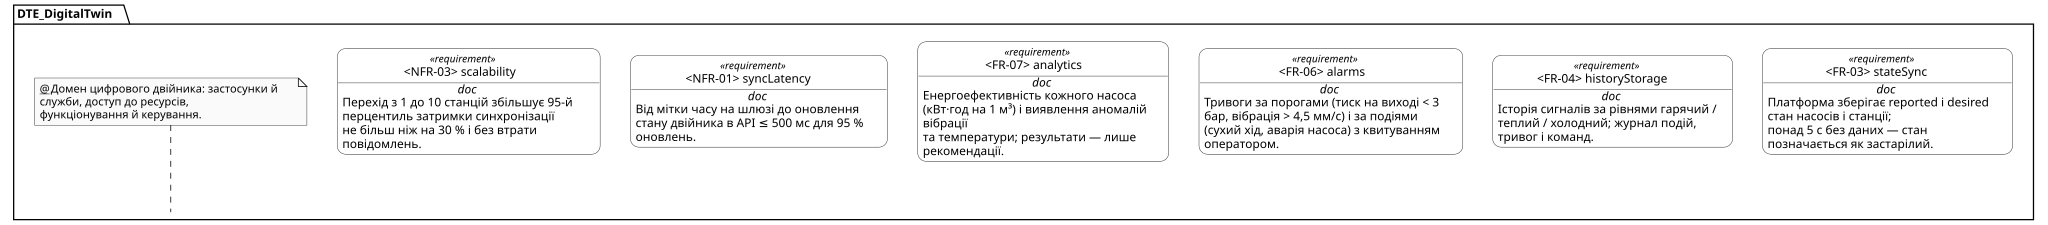

In [3]:
%viz --view=tree PumpStationTwin_Requirements::DTE_DigitalTwin

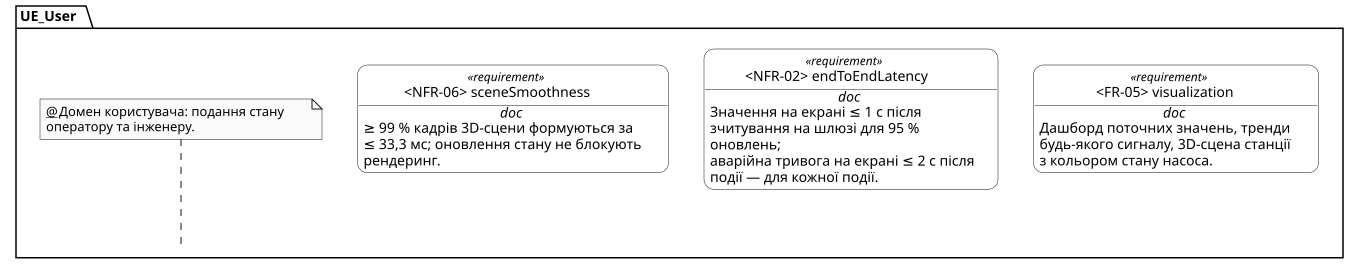

In [4]:
%viz --view=tree PumpStationTwin_Requirements::UE_User

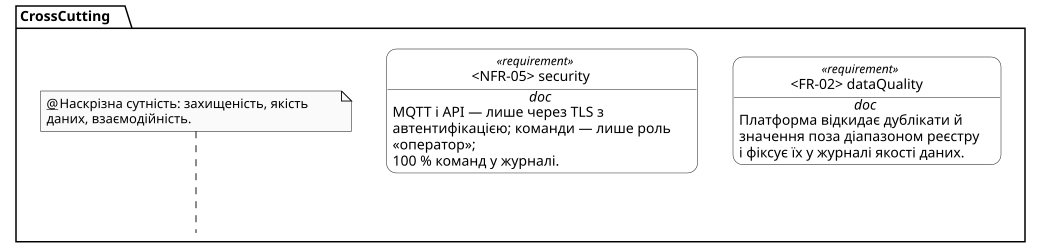

In [5]:
%viz --view=tree PumpStationTwin_Requirements::CrossCutting

## Крок 10. Структура і поведінка

**Структура.** Блоки — зі стовпця «Блок SysML» таблиці відповідності `docs/iso23247-mapping.md`; порти й з'єднання узгоджено з компонентним поданням `docs/diagrams/components.mmd`.

| Блок | Домен ISO 23247 | Технологія |
|---|---|---|
| `StationPLC` | OME (зовнішній елемент) | ПЛК із датчиками та ЧРП |
| `StationGateway` | DCE: збирання даних, керування пристроями | Python, промисловий ПК |
| `MqttBroker` | DCE: збирання даних | Eclipse Mosquitto |
| `SyncService` (`Validator`, `TwinUpdater`, `CommandDispatcher`, `HistoryWriter`) | DTE: функціонування та керування; наскрізна: якість даних | Python |
| `TwinStateService` | DTE: доступ до ресурсів та обмін | Eclipse Ditto |
| `HistoryStore` | DTE: доступ до ресурсів та обмін | TimescaleDB |
| `AnalyticsService` | DTE: застосунки та служби | Python |
| `WebApp` | UE | React, Three.js |
| `SecurityServices` | наскрізна: захищеність | nginx, ACL брокера, політики Ditto |

Типи портів відповідають протоколам: `OpcUa`, `Mqtt`, `TwinApi` (HTTP + SSE), `Sql`. `SecurityServices` — наскрізна служба без власних потоків даних, тому на діаграмі з'єднань вона без зв'язків.

In [6]:
package PumpStationTwin_Structure {
    doc /* Структура платформи: блоки зі стовпця «Блок SysML» таблиці відповідності ISO 23247
         * і з'єднання між ними, узгоджені з компонентним поданням components.mmd. */
    private import ISQ::*;
    private import SI::*;

    // Типи портів за протоколами обміну
    port def OpcUa  { doc /* OPC UA / Modbus: зчитування регістрів ПЛК, запис уставок */ }
    port def Mqtt   { doc /* MQTT: телеметрія й команди */ }
    port def TwinApi { doc /* HTTP API та події (SSE) сервісу стану двійника */ }
    port def Sql    { doc /* SQL: історія сигналів і журнал */ }

    // Зовнішній елемент (OME): контролер станції
    part def StationPLC {
        doc /* ПЛК станції з датчиками та ЧРП; регулювання тиску й захисти (ADR-0002). */
        port opcua : OpcUa;
    }

    // DCE: збирання даних і керування пристроями
    part def StationGateway {
        doc /* Шлюз станції: опитує ПЛК, рахує СКЗ вібрації (ADR-0003), ставить мітки часу, буферизує дані. */
        attribute rawVibrationRate : FrequencyValue = 2560 [Hz];
        attribute vibrationRmsRate : FrequencyValue = 10 [Hz];
        attribute bufferDuration : DurationValue = 3600 [s];
        port plc : OpcUa;
        port mqtt : Mqtt;
    }
    part def MqttBroker {
        doc /* MQTT-брокер Eclipse Mosquitto. */
        port gw : Mqtt;
        port sub : Mqtt;
    }

    // DTE: функціонування та керування; наскрізна якість даних
    part def Validator         { doc /* Відкидає дублікати й значення поза діапазоном (FR-02). */ }
    part def TwinUpdater       { doc /* Оновлює reported-стан у сервісі стану двійника. */ }
    part def CommandDispatcher { doc /* Передає desired-стан на станцію, чекає підтвердження 10 с. */ }
    part def HistoryWriter     { doc /* Пакетно записує історію та журнал. */ }
    part def SyncService {
        doc /* Сервіс синхронізації. */
        attribute staleTimeout : DurationValue = 5 [s];
        attribute commandTimeout : DurationValue = 10 [s];
        part validator : Validator;
        part twinUpdater : TwinUpdater;
        part commandDispatcher : CommandDispatcher;
        part historyWriter : HistoryWriter;
        port mqtt : Mqtt;
        port twin : TwinApi;
        port db : Sql;
    }

    // DTE: доступ до ресурсів та обмін
    part def TwinStateService {
        doc /* Сервіс стану двійника Eclipse Ditto: reported / desired, тривоги; HTTP API та SSE. */
        port sync : TwinApi;
        port analytics : TwinApi;
        port web : TwinApi;
    }
    part def HistoryStore {
        doc /* Сховище часових рядів TimescaleDB (ADR-0001). */
        attribute rawRetention : DurationValue = 30 * 86400 [s];
        port sync : Sql;
        port analytics : Sql;
    }

    // DTE: застосунки та служби
    part def AnalyticsService {
        doc /* Енергоефективність, виявлення аномалій, тривоги за порогами. */
        port twin : TwinApi;
        port db : Sql;
        port web : TwinApi;
    }

    // UE: користувач
    part def WebApp {
        doc /* Веб-застосунок: дашборд, тренди, 3D-сцена (React, Three.js). */
        attribute frameBudget : DurationValue = 0.0333 [s];
        port twin : TwinApi;
        port analytics : TwinApi;
    }

    // Наскрізна сутність: захищеність
    part def SecurityServices {
        doc /* Наскрізна служба: TLS, автентифікація, ролі й журнал команд для брокера, API двійника
             * та веб-застосунку (nginx, ACL брокера, політики Ditto). Як наскрізна сутність ISO 23247
             * не має власних потоків даних, тому на діаграмі з'єднань показана без зв'язків. */
    }

    part def Platform {
        doc /* Платформа цифрового двійника насосної станції. */
        part gateway : StationGateway;
        part broker : MqttBroker;
        part sync : SyncService;
        part twinState : TwinStateService;
        part history : HistoryStore;
        part analytics : AnalyticsService;
        part webApp : WebApp;
        part security : SecurityServices;

        connect gateway.mqtt to broker.gw;
        connect broker.sub to sync.mqtt;
        connect sync.twin to twinState.sync;
        connect sync.db to history.sync;
        connect twinState.analytics to analytics.twin;
        connect analytics.db to history.analytics;
        connect twinState.web to webApp.twin;
        connect analytics.web to webApp.analytics;
    }

    part def PumpStationSystem {
        doc /* Насосна станція разом із платформою її цифрового двійника. */
        part plc : StationPLC;
        part platform : Platform;
        connect plc.opcua to platform.gateway.plc;
    }

    part pumpStationSystem : PumpStationSystem;
}


Package PumpStationTwin_Structure (0359635d-5df8-422a-b27b-53ccfb3e4b02)


### Діаграма блоків платформи (з'єднання через порти)

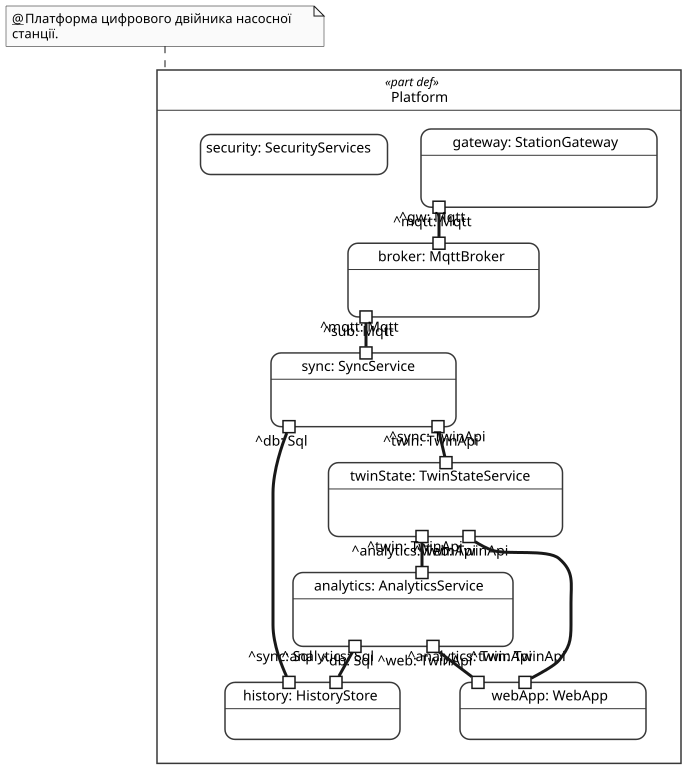

In [7]:
%viz --view=interconnection PumpStationTwin_Structure::Platform

**Поведінка.** Ключовий сценарій «надходження відліку — валідація — оновлення стану двійника — сповіщення інтерфейсу»; запис в історію йде паралельною гілкою, як на `docs/diagrams/dataflow.mmd`.

In [8]:
package PumpStationTwin_Behavior {
    doc /* Ключовий сценарій: надходження відліку — валідація — оновлення стану двійника — сповіщення інтерфейсу. */

    item def TelemetrySample {
        attribute signalId : ScalarValues::String;
        attribute timestamp : ScalarValues::Real;
        attribute value : ScalarValues::Real;
    }

    action def ProcessTelemetrySample {
        in item sample : TelemetrySample;
        attribute isValid : ScalarValues::Boolean;

        first start;
        then action receiveSample  { doc /* Сервіс синхронізації отримує відлік від MQTT-брокера. */ }
        then action validateSample { doc /* Перевірка дубліката й діапазону з реєстру сигналів (FR-02). */ }
        then decide checkValid;
            if isValid then updateReportedState;
            else rejectSample;

        action rejectSample { doc /* Відлік відкинуто й записано в журнал якості даних. */ }
        then done;

        action updateReportedState { doc /* Оновлення reported-стану в Ditto; скидання позначки «застарілий». */ }
        then fork forkNotify;
            then notifyWebApp;
            then writeHistory;

        action notifyWebApp { doc /* Ditto надсилає подію зміни стану у веб-застосунок через SSE. */ }
        then joinDone;
        action writeHistory { doc /* Паралельна гілка: пакетний запис в історію (TimescaleDB). */ }
        then joinDone;

        join joinDone;
        then done;
    }
}


Package PumpStationTwin_Behavior (6d81adc1-b7e0-498a-afdc-af55d0c34ce8)


### Діаграма діяльності

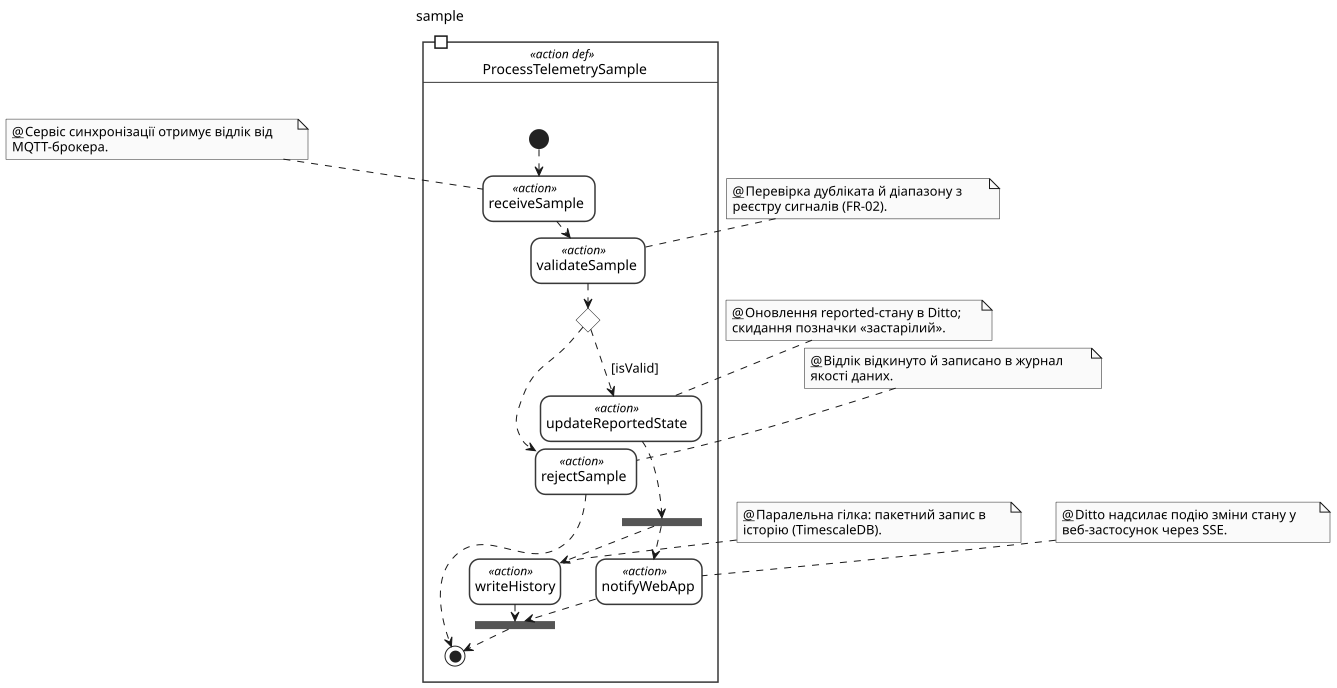

In [9]:
%viz --view=action PumpStationTwin_Behavior::ProcessTelemetrySample

## Крок 11. Трасовність

Кожну вимогу пов'язано з блоком, що її задовольняє (`satisfy`), і з перевіркою, що її підтверджує (`verify`). Матрицю й показники покриття наведено в `docs/traceability.md`: Cт = Cв = 100 %.

In [10]:
package PumpStationTwin_Traceability {
    doc /* Трасовність: кожна вимога пов'язана з блоком, що її задовольняє (satisfy),
         * і з перевіркою, що її підтверджує (verify). */
    private import PumpStationTwin_Requirements::DCE_DeviceCommunication::*;
    private import PumpStationTwin_Requirements::DTE_DigitalTwin::*;
    private import PumpStationTwin_Requirements::UE_User::*;
    private import PumpStationTwin_Requirements::CrossCutting::*;
    private import PumpStationTwin_Structure::*;

    // ---------- satisfy: вимога → блок ----------
    satisfy telemetryCollection by pumpStationSystem.platform.gateway;
    satisfy telemetryCollection by pumpStationSystem.platform.broker;
    satisfy dataQuality         by pumpStationSystem.platform.sync.validator;
    satisfy stateSync           by pumpStationSystem.platform.sync.twinUpdater;
    satisfy stateSync           by pumpStationSystem.platform.twinState;
    satisfy historyStorage      by pumpStationSystem.platform.sync.historyWriter;
    satisfy historyStorage      by pumpStationSystem.platform.history;
    satisfy visualization       by pumpStationSystem.platform.webApp;
    satisfy alarms              by pumpStationSystem.platform.analytics;
    satisfy analytics           by pumpStationSystem.platform.analytics;
    satisfy remoteControl       by pumpStationSystem.platform.sync.commandDispatcher;
    satisfy remoteControl       by pumpStationSystem.platform.gateway;
    satisfy syncLatency         by pumpStationSystem.platform.sync;
    satisfy syncLatency         by pumpStationSystem.platform.twinState;
    satisfy endToEndLatency     by pumpStationSystem.platform.twinState;
    satisfy endToEndLatency     by pumpStationSystem.platform.webApp;
    satisfy scalability         by pumpStationSystem.platform.broker;
    satisfy scalability         by pumpStationSystem.platform.sync;
    satisfy commandLatency      by pumpStationSystem.platform.sync.commandDispatcher;
    satisfy security            by pumpStationSystem.platform.security;
    satisfy sceneSmoothness     by pumpStationSystem.platform.webApp;

    // ---------- verify: перевірка → вимога ----------
    verification def <'VC-01'> TelemetryTest     { objective { verify telemetryCollection; } }
    verification def <'VC-02'> ValidationTest    { objective { verify dataQuality; } }
    verification def <'VC-03'> StateSyncTest     { objective { verify stateSync; } }
    verification def <'VC-04'> StorageTest       { objective { verify historyStorage; } }
    verification def <'VC-05'> VisualizationTest { objective { verify visualization; } }
    verification def <'VC-06'> AlarmTest         { objective { verify alarms; } }
    verification def <'VC-07'> AnalyticsTest     { objective { verify analytics; } }
    verification def <'VC-08'> CommandTest       { objective { verify remoteControl; } }
    verification def <'VC-09'> SyncLatencyTest   { objective { verify syncLatency; } }
    verification def <'VC-10'> EndToEndTest      { objective { verify endToEndLatency; } }
    verification def <'VC-11'> LoadTest          { objective { verify scalability; } }
    verification def <'VC-12'> CommandLatencyTest { objective { verify commandLatency; } }
    verification def <'VC-13'> SecurityTest      { objective { verify security; } }
    verification def <'VC-14'> FrameTimeTest     { objective { verify sceneSmoothness; } }
}


Package PumpStationTwin_Traceability (3d5fd354-a31f-4318-b0e8-237efc7f3aa3)
